Identifikation von Energiesparmaßnahmen für das Laden von Elektrofahzeugen in gewerblicher Nutzung:
- Eigene Messungen durch Energielogger
- Datensatz der Stadt München (4 Ladepunkte, 2054 Ladeprozesse)
- Bewertung von 10 Energiesparmaßnahmen
- Genauere Betrachtung von 3 Maßnahmen > 5 % Einsparung

## **2. Bibliotheken importieren/ Parameter festlegen:**

In [1]:
# Python Bibliotheken importieren
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import shutil
import pandas as pd
import schemdraw
from schemdraw import flow
import schemdraw.elements as elm
from IPython.display import Markdown, display
from sympy import false

print('Python module versions used:')
print('matplotlib', matplotlib.__version__)
print('numpy', np.__version__)
print('shutil', shutil)

Python module versions used:
matplotlib 3.10.3
numpy 1.26.4
shutil <module 'shutil' from 'C:\\Users\\Felix\\AppData\\Local\\Programs\\Python\\Python311\\Lib\\shutil.py'>


In [2]:
# Präsenations Parameter festlegen
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['figure.autolayout'] = False
plt.rcParams['figure.figsize'] = 10, 6
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['font.size'] = 18
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 18
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16

if shutil.which('latex'): plt.rcParams['text.usetex'] = True

#pip show RISE
#pip show jupyterlab_rise

## **4. Datengrundlage**

#### 4.1 Datenquelle und Rahmenbedingungen

Echte Messdaten aus dem Projekt **'München elektrisiert'** [1]:
- 4 "Ladepunkte" (**3 Schnellladestationen** + ~~agglomerierte Wallboxen~~)
- 2054 Ladeprozesse (**1943** + ~~111~~)
- Messzeitraum: **2019** bis **2021**
- Auflösung: **5 min**
- 26 verschiedene Messgrößen (relevant: **active_power_total**)
<br>

- ffe_active_power_all_long.csv mit active_power_total als Grundlage der weiteren Berechnung
    - Mittels **fetch_data_api.py** und **extract_active_power_all.py** erzeugt (siehe Anhang)

In [3]:
#zweiter import weil shemdraw nicht installiert
import pandas as pd

df = pd.read_csv("ffe_active_power_all_long.csv", parse_dates=["timestamp"])
df = df.sort_values(["process_id", "timestamp"])

# Timestamp-Spalte in datetime umwandeln
df['timestamp'] = pd.to_datetime(df['timestamp'])
# Timestamp als Index setzen
df = df.set_index('timestamp')
df = df.drop(columns=['timestamp_unix'])


#negative Werte filtern
df["active_power_total"] = df["active_power_total"].clip(lower=0)
#print((df["active_power_total"] < 0).any())

#charging points trennen und mit Timeindex und Null Werten versehen
dfs_full = {}

for cp_id in [2, 3, 4]:
    df_cp = df[df["charging_point_id"] == cp_id].copy()

    full_index = pd.date_range(
        start=df_cp.index.min().floor("5min"),
        end=df_cp.index.max().ceil("5min"),
        freq="5min"
    )

    df_cp_full = df_cp.reindex(full_index)

    df_cp_full["charging_point_id"] = df_cp_full["charging_point_id"].fillna(cp_id)
    df_cp_full["active_power_total"] = df_cp_full["active_power_total"].fillna(0)
  #  df_cp_full["process_id"] = df_cp_full["process_id"].fillna(0)

    dfs_full[cp_id] = df_cp_full

df_all = pd.concat(
    [dfs_full[2], dfs_full[3], dfs_full[4]],
    axis=0
)

#print(df_all)
df2 = df_all[df_all["charging_point_id"] == 2].copy()
df3 = df_all[df_all["charging_point_id"] == 3].copy()
df4 = df_all[df_all["charging_point_id"] == 4].copy()

#generieren einer Liste mit allen Prozess IDs der jeweiligen Ladepunkte
process_ids_2 = (df2["process_id"].dropna().unique().tolist())
process_ids_3 = (df3["process_id"].dropna().unique().tolist())
process_ids_4 = (df4["process_id"].dropna().unique().tolist())
#print(process_ids_4)

### 4.2 Veranschaulichung der Daten

#### Definition der plot Funktionen


In [4]:
### COMPUTE STATS

import pandas as pd
from typing import Optional, List, Union

def compute_stats_df(
    df: pd.DataFrame,
    process_ids: Optional[List[Union[int, float]]] = None,
    power_col: str = "active_power_total",
    process_col: str = "process_id",
    cp_col: str = "charging_point_id",
    drop_zero_process: bool = True
) -> pd.DataFrame:
    """
    Berechnet Statistiken pro Ladevorgang (process_id).

    Input df:
    - DatetimeIndex (timestamp)
    - Spalten: process_id, charging_point_id, active_power_total

    Optional:
    - process_ids: Liste von process_id, die ausgewertet werden sollen.
                  Wenn None: alle vorhandenen process_id werden genommen.
    """

    # --- Safety check: timestamp muss Index sein ---
    if not isinstance(df.index, pd.DatetimeIndex):
        raise ValueError("df muss einen DatetimeIndex haben (timestamp als Index).")

    d = df.copy()

    # --- 1) Nur echte Prozesse behalten ---
    # Zeilen aus dem 5-min-Reindex ohne process_id sind außerhalb von Ladevorgängen
    d = d[d[process_col].notna()].copy()

    # Optional: process_id == 0 als "kein Prozess" behandeln
    if drop_zero_process:
        d = d[d[process_col] != 0].copy()

    # --- 2) Optional: auf bestimmte process_ids filtern ---
    # Damit kannst du gezielt einzelne Ladevorgänge analysieren
    if process_ids is not None:
        d = d[d[process_col].isin(process_ids)].copy()

    # --- 3) Sortierung: erst nach Prozess, dann zeitlich ---
    # Für dt-Berechnung muss die Reihenfolge innerhalb der Prozesse stimmen
    d = d.sort_values(process_col)
    d = d.sort_index()

    # --- 4) Zeitdifferenz dt_h pro Prozess (in Stunden) ---
    # Index als Series, nach process_id gruppieren, diff() berechnet Delta zum vorherigen Zeitstempel
    d["dt_h"] = (
        pd.Series(d.index, index=d.index)
        .groupby(d[process_col])
        .diff()
        .dt.total_seconds()
        .div(3600)
        .fillna(0)  # erste Zeile je Prozess -> keine Vorgänger-Zeit -> 0 h
    )

    # --- 5) Energieinkrement pro Zeitschritt ---
    # kW * h = kWh
    d["dE_kWh"] = d[power_col] * d["dt_h"]

    # --- 6) Aggregation: eine Zeile pro process_id ---
    # start/end kommen aus dem Index (Zeitstempel), daher nutzen wir eine kleine Funktion auf s.index
    stats = d.groupby(process_col).agg(
        charging_point_id=(cp_col, "first"),
        start=(power_col, lambda s: s.index.min()),
        end=(power_col, lambda s: s.index.max()),
        duration_h=("dt_h", "sum"),
        mean_power=(power_col, "mean"),
        max_power=(power_col, "max"),
        energy_kWh=("dE_kWh", "sum"),
        n_points=(power_col, "size"),
    )

    stats.index.name = "process_id"
    return stats


### BOXPLOTS

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from typing import Literal, Optional

PlotKind = Literal[
    "energy_weekday",
    "energy_cp",
    "max_weekday",
    "max_cp",
    "mean_weekday",
    "mean_cp",
    "duration_weekday",
    "duration_cp",
    "power_weekday_combo",
    "power_cp_combo",
]

def plot_stats_boxplot(stats: pd.DataFrame,
                       kind: PlotKind,
                       figsize: tuple = (11, 5),
                       showfliers: bool = True,
                       rotate_x: int = 0,
                       weekday_labels_de: bool = False,) -> None:


    """
    Erstellt genau EINEN gewünschten Boxplot aus dem 'stats'-DataFrame (Output von compute_stats_df).

    kind:
      - "energy_weekday"        Energie (kWh) nach Wochentag (aus start)
      - "energy_cp"             Energie (kWh) nach Charging Point
      - "max_weekday"           Max-Leistung (kW) nach Wochentag
      - "max_cp"                Max-Leistung (kW) nach Charging Point
      - "mean_weekday"          Mean-Leistung (kW) nach Wochentag
      - "mean_cp"               Mean-Leistung (kW) nach Charging Point
      - "duration_weekday"      Dauer (h) nach Wochentag
      - "duration_cp"           Dauer (h) nach Charging Point
      - "power_weekday_combo"   2 Boxen pro Wochentag: Mean vs Max
      - "power_cp_combo"        2 Boxen pro CP: Mean vs Max
    """

    s = stats.copy()

    # --- start muss datetime sein (für weekday plots) ---
    if "start" in s.columns:
        s["start"] = pd.to_datetime(s["start"])

    # --- Wochentag vorbereiten (nur falls benötigt) ---
    need_weekday = kind in {
        "energy_weekday", "max_weekday", "mean_weekday", "duration_weekday", "power_weekday_combo"
    }
    if need_weekday:
        if "start" not in s.columns:
            raise ValueError("Für Wochentags-Plots muss 'start' in stats vorhanden sein.")
        s["weekday_name"] = s["start"].dt.day_name()

        weekday_order_en = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
        if weekday_labels_de:
            # Mapping für Anzeige
            map_de = {
                "Monday": "Mo", "Tuesday": "Di", "Wednesday": "Mi", "Thursday": "Do",
                "Friday": "Fr", "Saturday": "Sa", "Sunday": "So",
            }
            s["weekday_name"] = s["weekday_name"].map(map_de)
            weekday_order = ["Mo", "Di", "Mi", "Do", "Fr", "Sa", "So"]
        else:
            weekday_order = weekday_order_en

    plt.figure(figsize=figsize)

    # =========================
    # Einzelmetric-Boxplots
    # =========================
    if kind == "energy_weekday":
        ax = sns.boxplot(data=s, x="weekday_name", y="energy_kWh",
                         order=weekday_order, showfliers=showfliers)
        ax.set_title("Energie pro Ladevorgang nach Wochentag")
        ax.set_xlabel("Wochentag")
        ax.set_ylabel("Energie (kWh)")

    elif kind == "energy_cp":
        ax = sns.boxplot(data=s, x="charging_point_id", y="energy_kWh", showfliers=showfliers)
        ax.set_title("Energie pro Ladevorgang nach Charging Point")
        ax.set_xlabel("Charging Point")
        ax.set_ylabel("Energie (kWh)")

    elif kind == "max_weekday":
        ax = sns.boxplot(data=s, x="weekday_name", y="max_power",
                         order=weekday_order, showfliers=showfliers)
        ax.set_title("Maximale Leistung pro Ladevorgang nach Wochentag")
        ax.set_xlabel("Wochentag")
        ax.set_ylabel("Max-Leistung (kW)")

    elif kind == "max_cp":
        ax = sns.boxplot(data=s, x="charging_point_id", y="max_power", showfliers=showfliers)
        ax.set_title("Maximale Leistung pro Ladevorgang nach Charging Point")
        ax.set_xlabel("Charging Point")
        ax.set_ylabel("Max-Leistung (kW)")

    elif kind == "mean_weekday":
        ax = sns.boxplot(data=s, x="weekday_name", y="mean_power",
                         order=weekday_order, showfliers=showfliers)
        ax.set_title("Durchschnittliche Leistung pro Ladevorgang nach Wochentag")
        ax.set_xlabel("Wochentag")
        ax.set_ylabel("Mean-Leistung (kW)")

    elif kind == "mean_cp":
        ax = sns.boxplot(data=s, x="charging_point_id", y="mean_power", showfliers=showfliers)
        ax.set_title("Durchschnittliche Leistung pro Ladevorgang nach Charging Point")
        ax.set_xlabel("Charging Point")
        ax.set_ylabel("Mean-Leistung (kW)")

    elif kind == "duration_weekday":
        ax = sns.boxplot(data=s, x="weekday_name", y="duration_h",
                         order=weekday_order, showfliers=showfliers)
        ax.set_title("Ladedauer pro Ladevorgang nach Wochentag")
        ax.set_xlabel("Wochentag")
        ax.set_ylabel("Dauer (h)")

    elif kind == "duration_cp":
        ax = sns.boxplot(data=s, x="charging_point_id", y="duration_h", showfliers=showfliers)
        ax.set_title("Ladedauer pro Ladevorgang nach Charging Point")
        ax.set_xlabel("Charging Point")
        ax.set_ylabel("Dauer (h)")

    # =========================
    # Kombiplots (2 Boxen je Kategorie)
    # =========================
    elif kind in {"power_weekday_combo", "power_cp_combo"}:
        # Long-Format: damit hue=Metric zwei Boxen je Kategorie macht
        long_power = s.melt(
            id_vars=["weekday_name", "charging_point_id"] if kind == "power_weekday_combo" else ["charging_point_id"],
            value_vars=["mean_power", "max_power"],
            var_name="metric",
            value_name="power_kW",
        )
        long_power["metric"] = long_power["metric"].map({
            "mean_power": "Mean Power",
            "max_power": "Max Power",
        })

        if kind == "power_weekday_combo":
            ax = sns.boxplot(
                data=long_power,
                x="weekday_name",
                y="power_kW",
                hue="metric",
                order=weekday_order,
                showfliers=showfliers
            )
            ax.set_title("Mean vs Max Leistung nach Wochentag")
            ax.set_xlabel("Wochentag")
            ax.set_ylabel("Leistung (kW)")
        else:
            ax = sns.boxplot(
                data=long_power,
                x="charging_point_id",
                y="power_kW",
                hue="metric",
                showfliers=showfliers
            )
            ax.set_title("Mean vs Max Leistung nach Charging Point")
            ax.set_xlabel("Charging Point")
            ax.set_ylabel("Leistung (kW)")

        ax.legend(title="")

    else:
        raise ValueError(f"Unbekannter kind='{kind}'")

    plt.xticks(rotation=rotate_x, ha="center")
    plt.tight_layout()
    plt.show()


"""
    BOXPLOTS
    Erstellt genau EINEN gewünschten Boxplot aus dem 'stats'-DataFrame (Output von compute_stats_df). stats kann stats_all oder nur ein spezieller Ladepunkt sein, dann macht aber natürlich der vergleichende CP-Plot keinen Sinn.

    kind:
      - "energy_weekday"        Energie (kWh) nach Wochentag (aus start)
      - "energy_cp"             Energie (kWh) nach Charging Point
      - "max_weekday"           Max-Leistung (kW) nach Wochentag
      - "max_cp"                Max-Leistung (kW) nach Charging Point
      - "mean_weekday"          Mean-Leistung (kW) nach Wochentag
      - "mean_cp"               Mean-Leistung (kW) nach Charging Point
      - "duration_weekday"      Dauer (h) nach Wochentag
      - "duration_cp"           Dauer (h) nach Charging Point
      - "power_weekday_combo"   2 Boxen pro Wochentag: Mean vs Max
      - "power_cp_combo"        2 Boxen pro CP: Mean vs Max
"""



### HISTOGRAMME


def plot_hist_energy(stats, bins=50, log_y=False):
    x = stats["energy_kWh"].dropna()

    plt.figure(figsize=(10, 5))
    plt.hist(x, bins=bins)
    plt.xlabel("Energie pro Ladevorgang (kWh)")
    plt.ylabel("Anzahl Ladevorgänge")
    plt.title("Verteilung der Ladeenergie")
    if log_y:
        plt.yscale("log")
    plt.tight_layout()
    plt.show()


def plot_hist_max_power(stats, bins=50, log_y=False):
    x = stats["max_power"].dropna()

    plt.figure(figsize=(10, 5))
    plt.hist(x, bins=bins)
    plt.xlabel("Maximale Leistung pro Ladevorgang (kW)")
    plt.ylabel("Anzahl Ladevorgänge")
    plt.title("Verteilung der maximalen Ladeleistung")

    if log_y:
        plt.yscale("log")

    plt.tight_layout()
    plt.show()


def plot_hist_mean_power(stats, bins=50, log_y=False):
    x = stats["mean_power"].dropna()

    plt.figure(figsize=(10, 5))
    plt.hist(x, bins=bins)
    plt.xlabel("Durchschnittliche Leistung pro Ladevorgang (kW)")
    plt.ylabel("Anzahl Ladevorgänge")
    plt.title("Verteilung der durchschnittlichen Ladeleistung")

    if log_y:
        plt.yscale("log")

    plt.tight_layout()
    plt.show()



### MEHRERE LADEVORGÄNGE

import matplotlib.pyplot as plt
import pandas as pd
from typing import List, Union

def plot_multiple_processes(
    df: pd.DataFrame,
    process_ids: List[Union[int, float]],
    power_col: str = "active_power_total",
    process_col: str = "process_id",
    figsize: tuple = (12, 6),
    alpha: float = 0.8,
    show_legend: bool = True,
) -> None:
    """
    Plottet mehrere Ladeprofile (Leistung über Zeit) überlagert.
    Alle Ladeprofile starten bei t = 0 min (relativ zum jeweiligen Startzeitpunkt).

    Erwartetes df-Format:
    - DatetimeIndex (timestamp)
    - Spalten: process_id, active_power_total

    Parameters
    ----------
    df : DataFrame
        df2, df3, df4 oder df_all
    process_ids : list
        Liste der process_id, die geplottet werden sollen
    """

    if not isinstance(df.index, pd.DatetimeIndex):
        raise ValueError("df muss einen DatetimeIndex haben.")

    plt.figure(figsize=figsize)

    for pid in process_ids:
        # --- Daten für einen Ladevorgang ---
        dfp = df[df[process_col] == pid].copy()

        # Falls process_id nicht existiert (z.B. falsche Liste)
        if dfp.empty:
            continue

        # --- Zeit relativ zum Start (in Minuten) ---
        t0 = dfp.index.min()
        dfp["t_min"] = (dfp.index - t0).total_seconds() / 60

        # --- Plot ---
        plt.plot(
            dfp["t_min"],
            dfp[power_col],
            label=f"P{pid}",
            alpha=alpha,
        )

    plt.title("Überlagerte Ladeprofile (Zeit relativ zum Start)")
    plt.xlabel("Zeit seit Start [min]")
    plt.ylabel("Aktive Leistung [kW]")
    plt.grid(True)

    if show_legend:
        plt.legend()

    plt.tight_layout()
    plt.show()



### LADEVORGÄNE ÜBER DIE ZEIT

import pandas as pd
import matplotlib.pyplot as plt
from typing import List, Union

def plot_charging_processes_over_time(
    df: pd.DataFrame,
    process_ids: List[Union[int, float]],
    power_col: str = "active_power_total",
    process_col: str = "process_id",
    figsize: tuple = (14, 6),
    title: str = "Charging Processes Over Time",
    marker: str = None,          # z.B. "o" falls du Punkte willst
    linewidth: float = 1.8,
    alpha: float = 0.95,
    show_legend: bool = True,
    rotate_x: int = 45,
) -> None:
    """
    Plottet mehrere Ladevorgänge als "normale" Zeitreihe auf der echten Zeitachse
    (mit Lücken zwischen den Ladevorgängen, weil außerhalb der Prozesse keine Daten geplottet werden).

    Erwartetes df-Format:
    - DatetimeIndex (timestamp)
    - Spalten: process_id, active_power_total, (optional) charging_point_id

    Input:
    - df kann df2/df3/df4 oder df_all sein
    - process_ids ist die Liste der zu plottenden process_id
    """

    # --- Safety check: timestamp muss Index sein ---
    if not isinstance(df.index, pd.DatetimeIndex):
        raise ValueError("df muss einen DatetimeIndex haben (timestamp als Index).")

    plt.figure(figsize=figsize)

    for pid in process_ids:
        # Nur Daten dieses Ladevorgangs
        d = df[df[process_col] == pid]

        if d.empty:
            print(f"⚠️  process_id {pid} nicht gefunden")
            continue

        # Plot auf echter Zeitachse (Index)
        plt.plot(
            d.index,
            d[power_col],
            label=f"P{pid}",
            linewidth=linewidth,
            alpha=alpha,
            marker=marker,
        )

    plt.xlabel("Time")
    plt.ylabel("Active Power Total (kW)")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    if show_legend:
        plt.legend(loc="best")
    plt.xticks(rotation=rotate_x)
    plt.tight_layout()
    plt.show()



import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from typing import List, Union, Optional

def plot_charging_heatmap_null(
    df: pd.DataFrame,
    process_ids: Optional[List[Union[int, float]]] = None,
    power_col: str = "active_power_total",
    process_col: str = "process_id",
    figsize: tuple = (14, 8),
    cmap: str = "magma",
    title: str = "Charging Power Heatmap",
    aggfunc: str = "max",
    fill_value: float = 0.0,          # 0 => Nulltage sichtbar
    ytick_hourly: bool = True,        # nur jede Stunde anzeigen
    xtick_mode: str = "month",        # "month", "weekly", "none"
    xtick_rotation: int = 45,
) -> None:
    """
    Heatmap (mit Null-Füllung): X=Tage, Y=5-min Slots, Values=Leistung.
    Input: df2/df3/df4 oder df_all (DatetimeIndex).

    - process_ids: optional Filter auf konkrete Ladevorgänge
    - fill_value=0: auch Tage/Zeitslots ohne Daten werden als 0 gezeigt
    - xtick_mode="month": 1 Tick pro Monat
    """

    if not isinstance(df.index, pd.DatetimeIndex):
        raise ValueError("df muss einen DatetimeIndex haben (timestamp als Index).")

    d = df.copy()

    # --- optional: nur relevante Prozesse ---
    if process_ids is not None:
        d = d[d[process_col].isin(process_ids)].copy()

    # --- robuste Pivot-Schlüssel ---
    d["day"] = d.index.floor("D")            # Timestamp pro Tag
    d["tod"] = d.index.strftime("%H:%M")     # Time-of-day als String

    # --- vollständige Achsen erzwingen (zeigt auch leere Tage) ---
    all_days = pd.date_range(d["day"].min(), d["day"].max(), freq="D")
    all_tod = pd.date_range("00:00", "23:55", freq="5min").strftime("%H:%M")

    pivot = d.pivot_table(
        index="tod",
        columns="day",
        values=power_col,
        aggfunc=aggfunc
    )

    pivot = pivot.reindex(index=all_tod, columns=all_days)

    # --- Nulltage/Nullzeiten sichtbar machen ---
    if fill_value is not None:
        pivot = pivot.fillna(fill_value)

    plt.figure(figsize=figsize)
    ax = sns.heatmap(
        pivot,
        cmap=cmap,
        cbar_kws={"label": "Active Power (kW)"},
        linewidths=0.0,
        annot=False
    )

    # --- Y-Ticks: nur volle Stunden (jede 12. Zeile bei 5-min Raster) ---
    if ytick_hourly:
        step = 12
        y_pos = list(range(0, pivot.shape[0], step))
        ax.set_yticks(y_pos)
        ax.set_yticklabels(pivot.index[y_pos], rotation=0)

    # --- X-Ticks: 1 pro Monat (oder wöchentlich/none) ---
    cols = pd.DatetimeIndex(pivot.columns)

    if xtick_mode == "month":
        month_starts = cols.to_series().groupby([cols.year, cols.month]).head(1).index
        x_pos = [cols.get_loc(d) for d in month_starts]
        ax.set_xticks(x_pos)
        ax.set_xticklabels([d.strftime("%Y-%m") for d in month_starts],
                           rotation=xtick_rotation, ha="center")

    elif xtick_mode == "weekly":
        step = 7
        x_pos = list(range(0, pivot.shape[1], step))
        ax.set_xticks(x_pos)
        ax.set_xticklabels([cols[i].strftime("%d.%m") for i in x_pos],
                           rotation=xtick_rotation, ha="center")

    elif xtick_mode == "none":
        ax.set_xticks([])
        ax.set_xticklabels([])

    ax.set_xlabel("Datum")
    ax.set_ylabel("Uhrzeit (5-min)")
    ax.set_title(title)

    plt.tight_layout()
    plt.show()


### Abrufen der Plots

#### Statistiken

In [5]:


stats2 = compute_stats_df(df2)
#print(stats2)

#stats22 = compute_stats_df(df_all, process_ids_2)
#print(stats22)

stats_bsp = compute_stats_df(df_all, process_ids=[112.0, 888.0, 2054.0])
print('stats_bsp:')
print(stats_bsp)

stats_all = compute_stats_df(df_all)
print('\n \nstats_all: \n')
print(stats_all.drop(columns=["start", "end", "n_points"]))
print('\n \nstats_all describe: \n')
print(stats_all.describe().drop(columns=["start", "end", "n_points"]))
print('\nGesamtenergie aller Ladevorgänge:\n', stats_all["energy_kWh"].sum().round(2), 'kWh')

stats_bsp:
            charging_point_id               start                 end  \
process_id                                                              
112.0                     2.0 2019-12-17 07:45:00 2019-12-17 09:40:00   
888.0                     3.0 2020-02-23 10:35:00 2020-02-23 12:10:00   
2054.0                    4.0 2021-08-29 19:20:00 2021-08-29 20:05:00   

            duration_h  mean_power  max_power  energy_kWh  n_points  
process_id                                                           
112.0         1.916667   13.625388  29.099453   27.246329        24  
888.0         1.583333   36.633304  52.487465   61.049422        20  
2054.0        0.750000   17.122783  36.122658   14.264059        10  

 
stats_all: 

            charging_point_id  duration_h  mean_power  max_power  energy_kWh
process_id                                                                  
112.0                     2.0    1.916667   13.625388  29.099453   27.246329
113.0                     

#### Boxplots

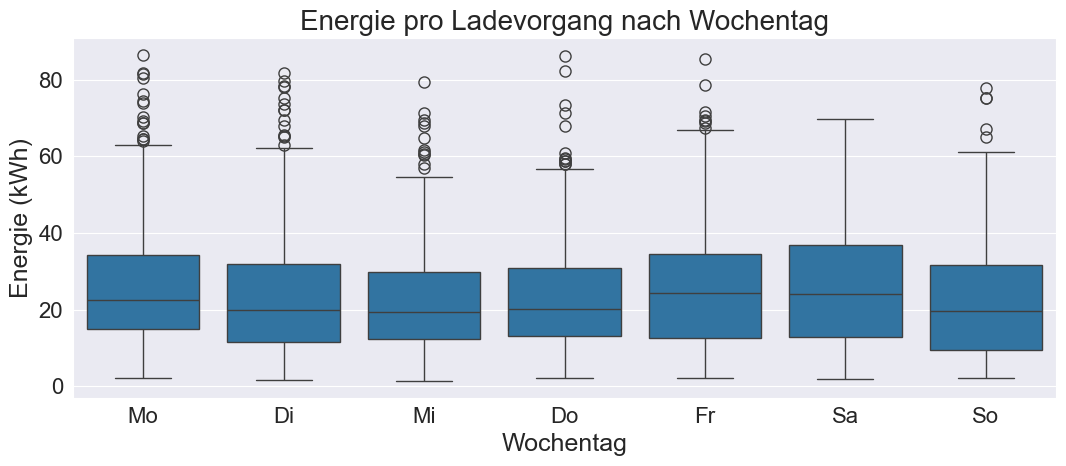

In [6]:
plot_stats_boxplot(stats_all, "energy_weekday", weekday_labels_de=True)
#plot_stats_boxplot(stats_all, "duration_weekday", weekday_labels_de=True)

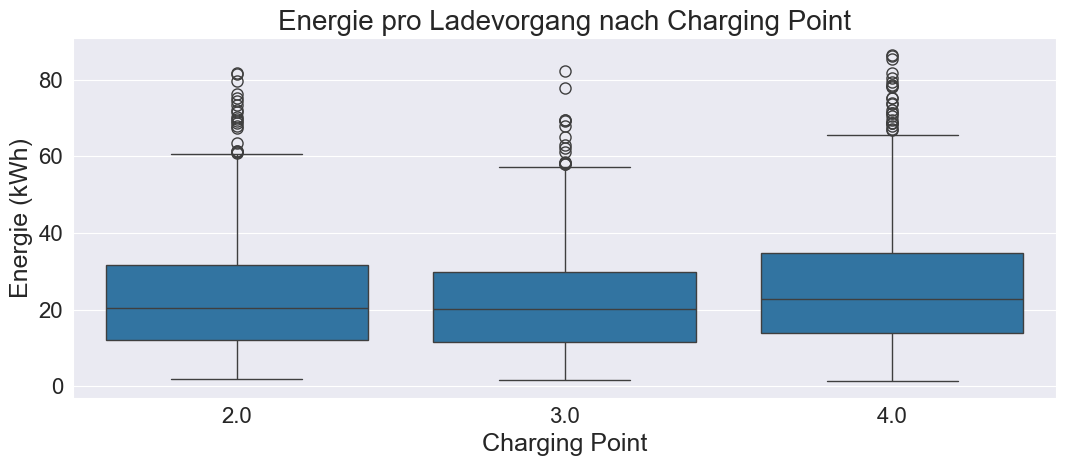

In [7]:
plot_stats_boxplot(stats_all, "energy_cp")

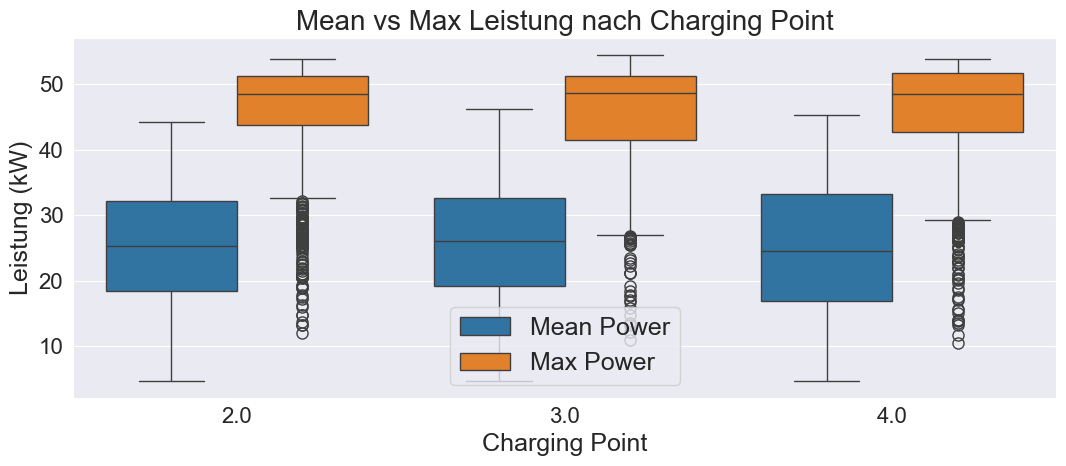

In [8]:
plot_stats_boxplot(stats_all, "power_cp_combo")
#plot_stats_boxplot(stats_all, "power_weekday_combo")

#### Histogramme

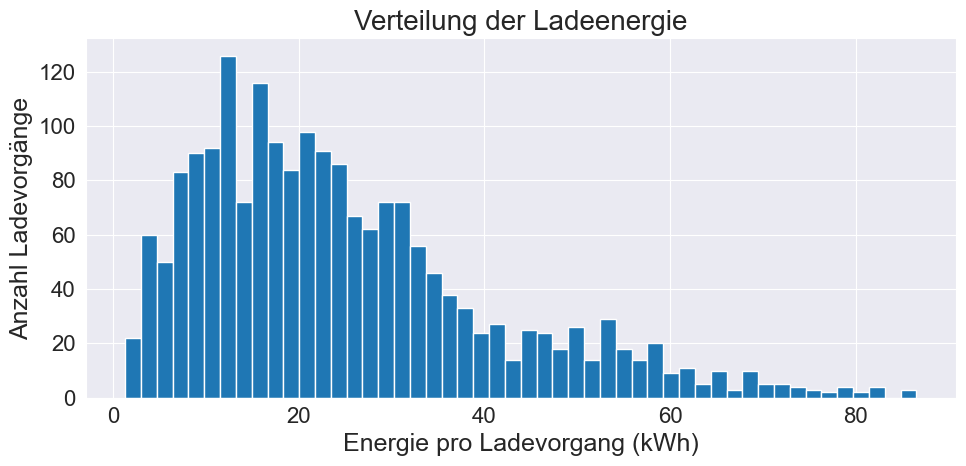

In [9]:
plot_hist_energy(stats_all)

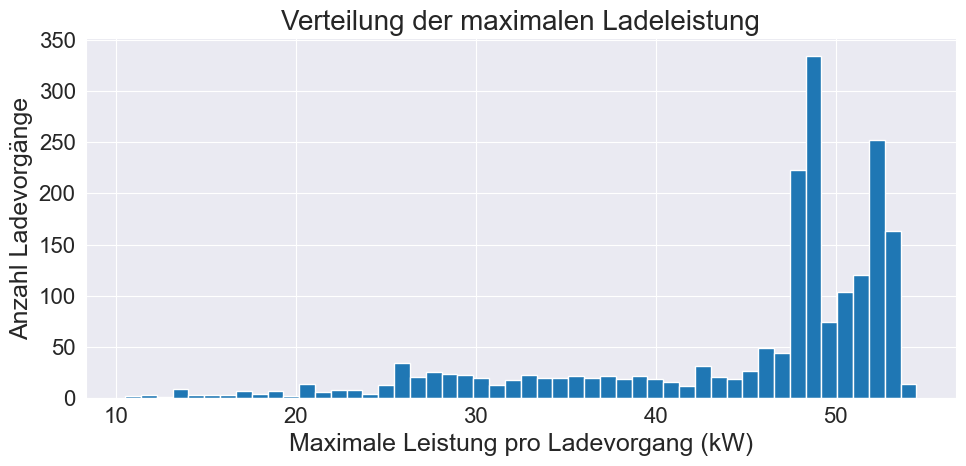

In [10]:
plot_hist_max_power(stats_all)#, log_y=True)

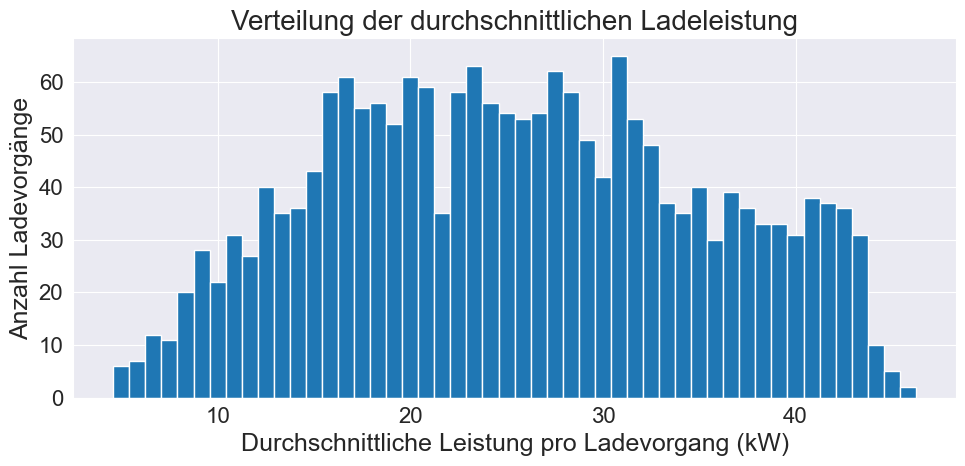

In [11]:
plot_hist_mean_power(stats_all)

#### Ladevorgänge

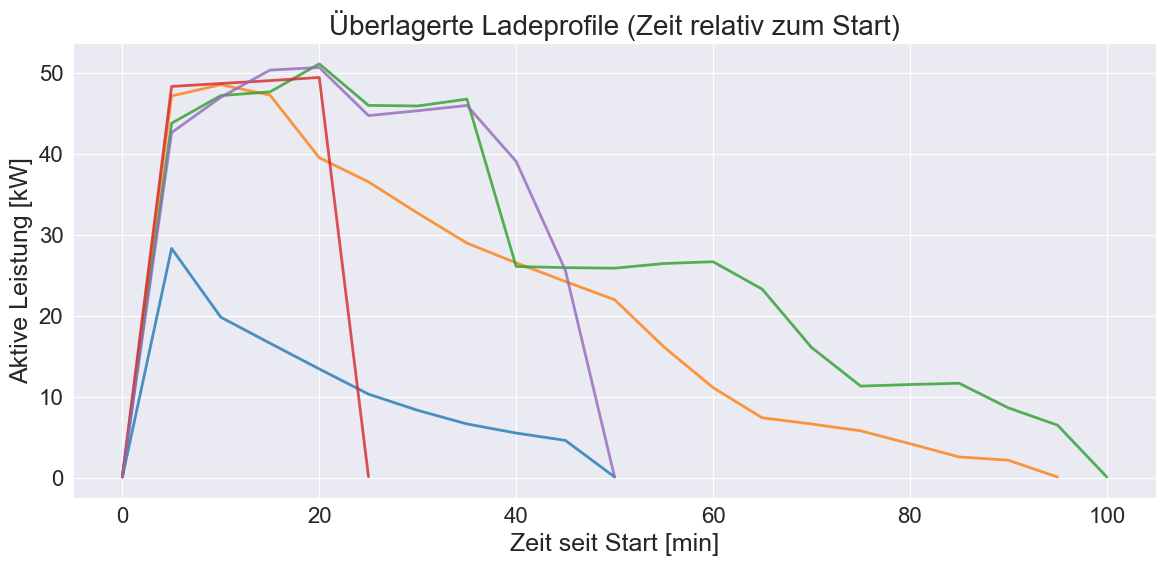

In [12]:
plot_multiple_processes(
    df_all,
    process_ids=process_ids_3[5:10],
    show_legend= False)

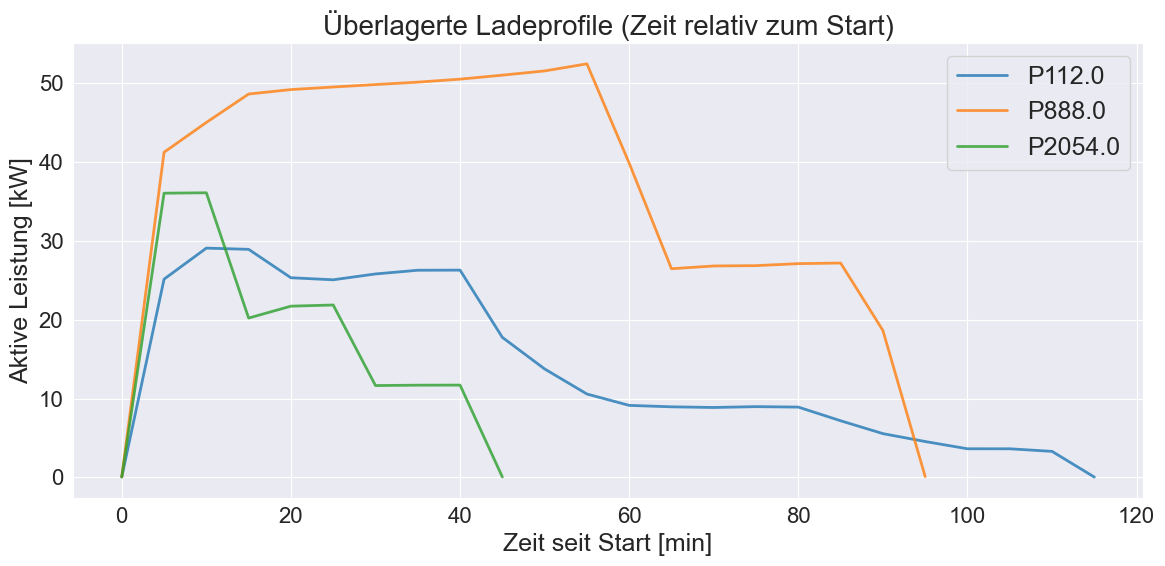

In [13]:
plot_multiple_processes(
    df_all,
    process_ids=[112.0, 888.0, 2054.0],
    show_legend= True)

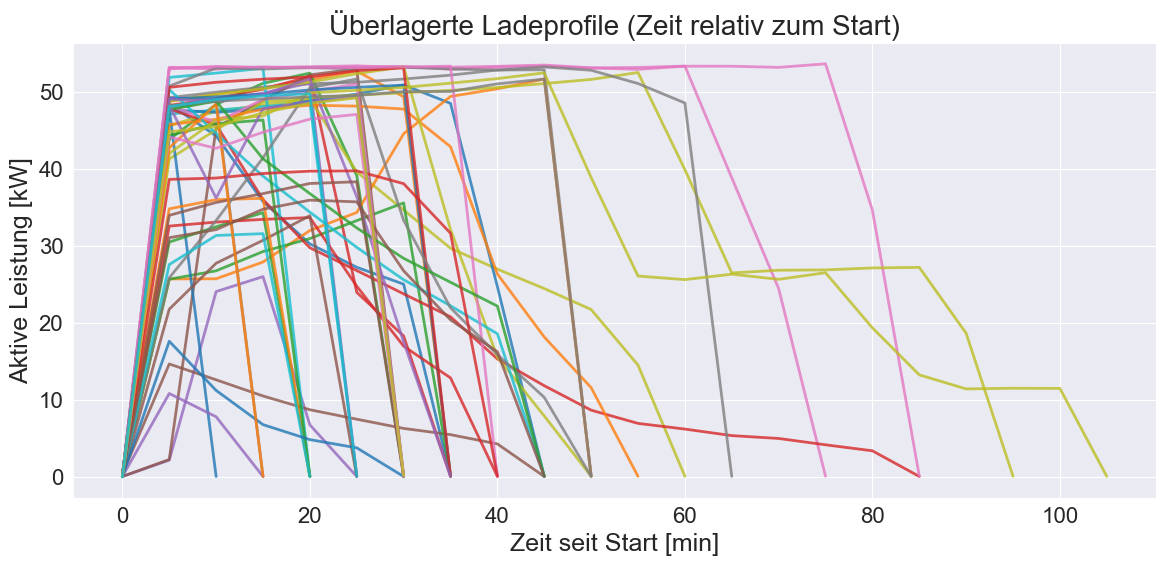

In [14]:
plot_multiple_processes(
    df_all,
    process_ids=process_ids_3[50:100],
    show_legend= False)

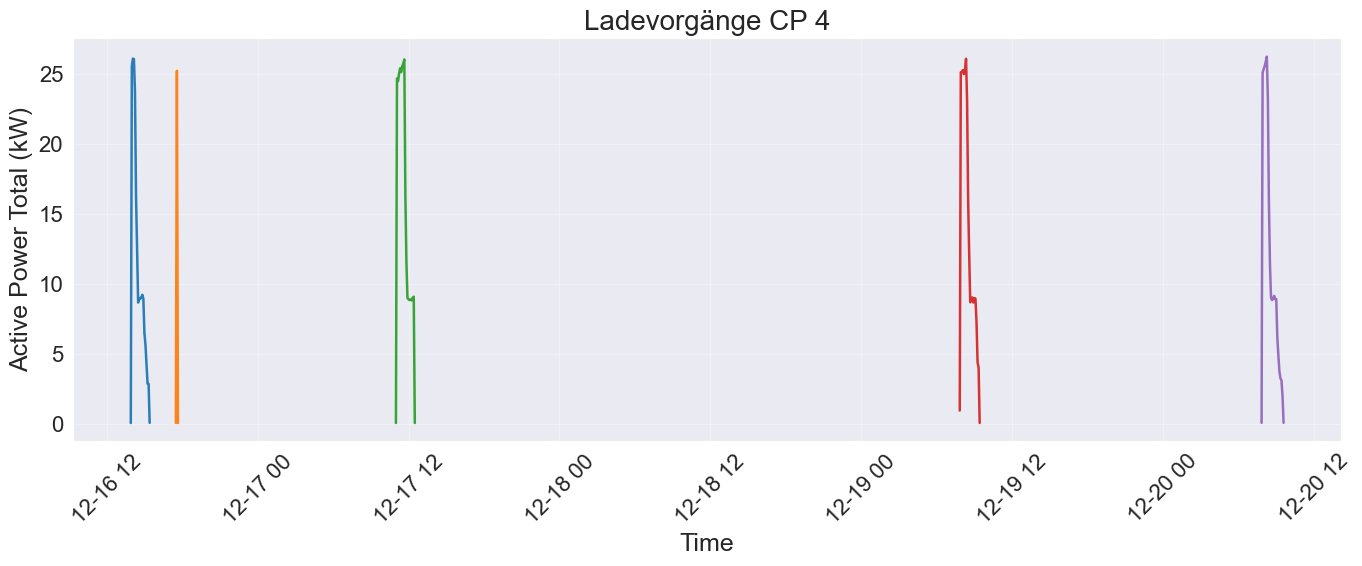

In [15]:
plot_charging_processes_over_time(df_all, process_ids=process_ids_4[:5], title="Ladevorgänge CP 4", show_legend=False)

#### Heatmaps

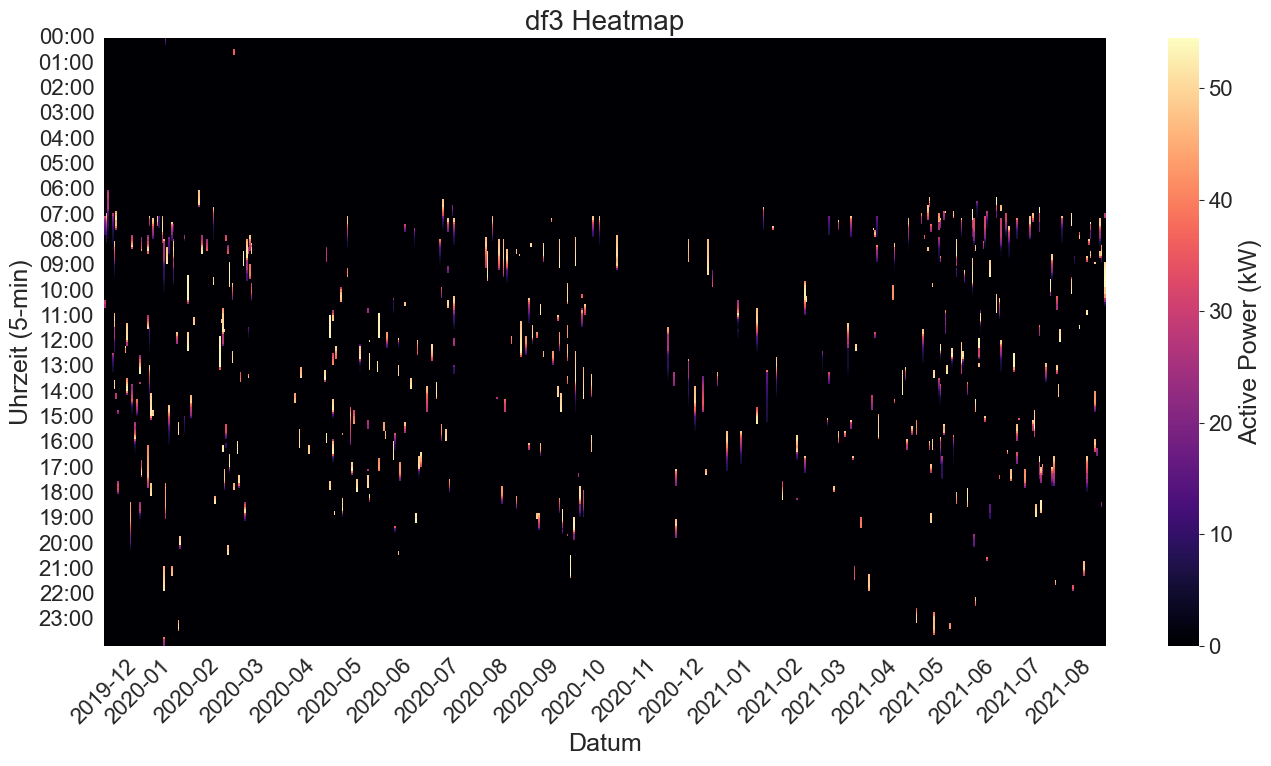

In [16]:
plot_charging_heatmap_null(df3, aggfunc="max", title="df3 Heatmap", cmap="magma")

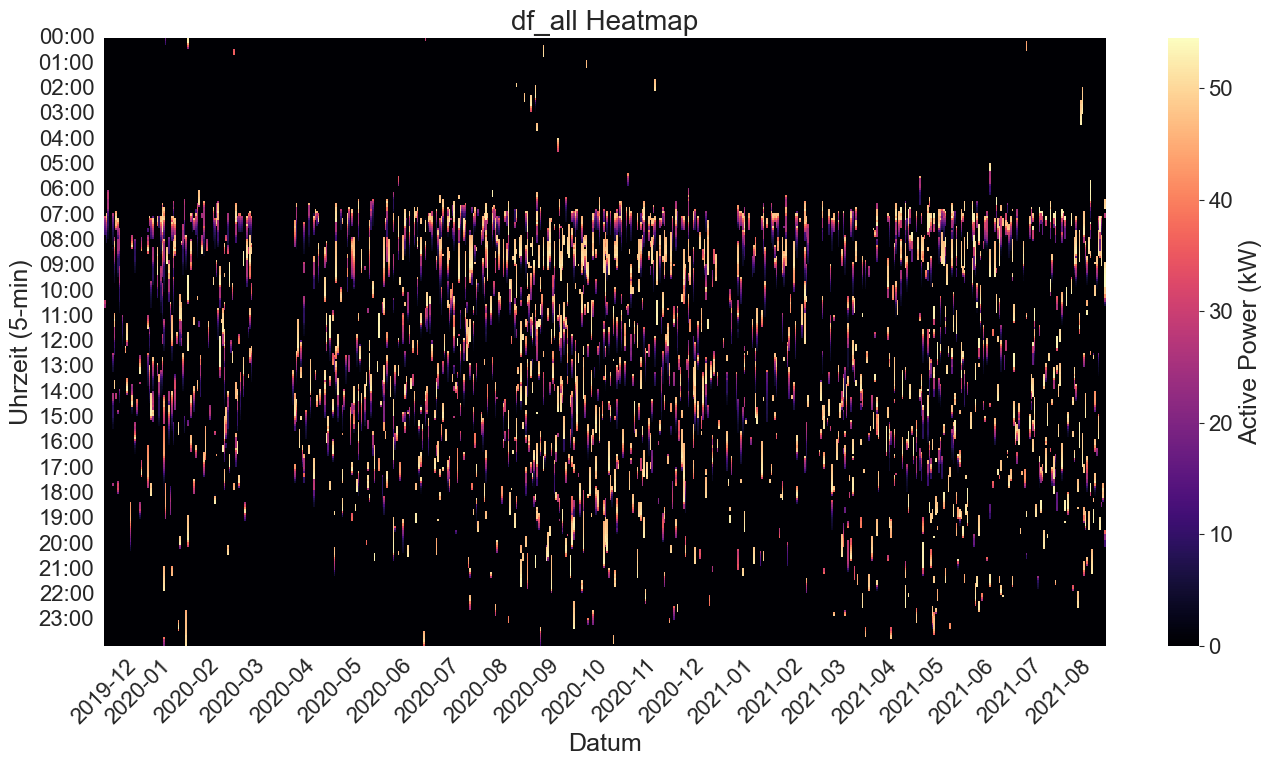

In [17]:
plot_charging_heatmap_null(df_all, aggfunc="max", title="df_all Heatmap", cmap="magma")

## **5. Szenario**

### 5.1 Szenario - Taxiunternehmen
- Vermittlung private Taxifahrer durch eine App (Klimaneutrales Huber)
- Registrierung der Taxifahren in unserem Unternehmen
- Diverse Fahrzeugflotte
- Exklusives Laden bei unserem Standort, kostengünstig

### **5.2 Systemskizze:**

In [18]:
def skizze(stats, bins=50, log_y=False):
    with schemdraw.Drawing(unit=1) as dw:
        # 1. Stromnetz (außerhalb)
        a = flow.RoundBox(w=3, h=2).at((-2, 0)).fill('lightskyblue').label('Stromnetz')
        dw.config(unit=.5)

        # Start der Systemgrenze
        with dw.container() as x:
            # Energiemanagementsystem
            b = flow.RoundBox(w=3, h=2).at((3, 0)).fill('mistyrose').label('Energie-\nmanagement-\nsystem')

            # Hilfspunkte für die Verzweigung (j, k, p)
            j = flow.State(w=0.15, h=0.15).at((7.9, 0))
            k = flow.State(w=0.15, h=0.15).at((13.9, 0))
            p = flow.State(w=0.15, h=0.15).at((19.9, 0))

            # --- Ladesäule 1 Container ---
            with dw.container() as ls1:
                acdc1 = flow.Box(w=3, h=1.2).at((6.5, -4.1)).fill('white').label('AC/DC', fontsize=10)
                dcdc1 = flow.Box(w=3, h=1.2).at((6.5, -6.1)).fill('white').label('DC/DC', fontsize=10)
                flow.Arrow(arrow='->').at(acdc1.S).to(dcdc1.N)
                ls1.label('Ladesäule 1', loc='N', color='black', fontsize=11)
                ls1.linestyle('--').fill('#f0f0f0')

            # --- Ladesäule 2 Container ---
            with dw.container() as ls2:
                acdc2 = flow.Box(w=3, h=1.2).at((14, -3.5)).fill('white').label('AC/DC', fontsize=10)
                dcdc2 = flow.Box(w=3, h=1.2).at((14, -5.5)).fill('white').label('DC/DC', fontsize=10)
                flow.Arrow(arrow='->').at(acdc2.S).to(dcdc2.N)
                ls2.label('Ladesäule 2', loc='N', color='black', fontsize=11)
                ls2.linestyle('--').fill('#f0f0f0')

            # --- Ladesäule 3 Container ---
            with dw.container() as ls3:
                acdc3 = flow.Box(w=3, h=1.2).at((20, -3.5)).fill('white').label('AC/DC', fontsize=10)
                dcdc3 = flow.Box(w=3, h=1.2).at((20, -5.5)).fill('white').label('DC/DC', fontsize=10)
                flow.Arrow(arrow='->').at(acdc3.S).to(dcdc3.N)
                ls3.label('Ladesäule 3', loc='N', color='black', fontsize=11)
                ls3.linestyle('--').fill('#f0f0f0')

            # Elektroautos
            g = flow.RoundBox(w=3, h=2).at((8, -9)).fill('lightskyblue').label('Elektroauto')
            m = flow.RoundBox(w=3, h=2).at((14, -9)).fill('lightskyblue').label('Elektroauto')
            o = flow.RoundBox(w=3, h=2).at((20, -9)).fill('lightskyblue').label('Elektroauto')

            # Systemgrenze Styling
            x.color('red').linestyle('--')
            x.label('Systemgrenze', loc='N', valign='top', color='red')

        # 3. Pfeile und Verbindungen
        flow.Arrow(arrow='->').at(a.E).to(b.W).color('black')

        # Hauptleitung oben
        flow.Line(arrow='-').at(b.E).to(j.W).color('black')
        flow.Line(arrow='-').at(j.E).to(k.W).color('black')
        flow.Line(arrow='-').at(k.E).to(p.W).color('black')

        # Stichleitungen zu den Ladesäulen (AC/DC Wandlern)
        flow.Arrow(arrow='->').at(j.S).to(acdc1.N).color('black')
        flow.Arrow(arrow='->').at(k.S).to(acdc2.N).color('black')
        flow.Arrow(arrow='->').at(p.S).to(acdc3.N).color('black')

        # Von den Ladesäulen (DC/DC Wandlern) zu den Autos
        flow.Arrow(arrow='->').at(dcdc1.S).to(g.N).color('black')
        flow.Arrow(arrow='->').at(dcdc2.S).to(m.N).color('black')
        flow.Arrow(arrow='->').at(dcdc3.S).to(o.N).color('black')

        # Pfeil von Elektroauto 1 (g) nach links aus der Systemgrenze
        flow.Arrow(arrow='->').at(g.S).down(2.5).label('Fahrleistung', loc='bottom').color('black')
        flow.Arrow(arrow='->').at(m.S).down(2.5).label('Fahrleistung', loc='bottom').color('black')
        flow.Arrow(arrow='->').at(o.S).down(2.5).label('Fahrleistung', loc='bottom').color('black')

        # Ein Pfeil, der bei x=5, y=-12 startet und 3 Einheiten nach links geht
        flow.Arrow(arrow='->').at((22.5, -5)).right(3).label('Abwärme', loc='top')


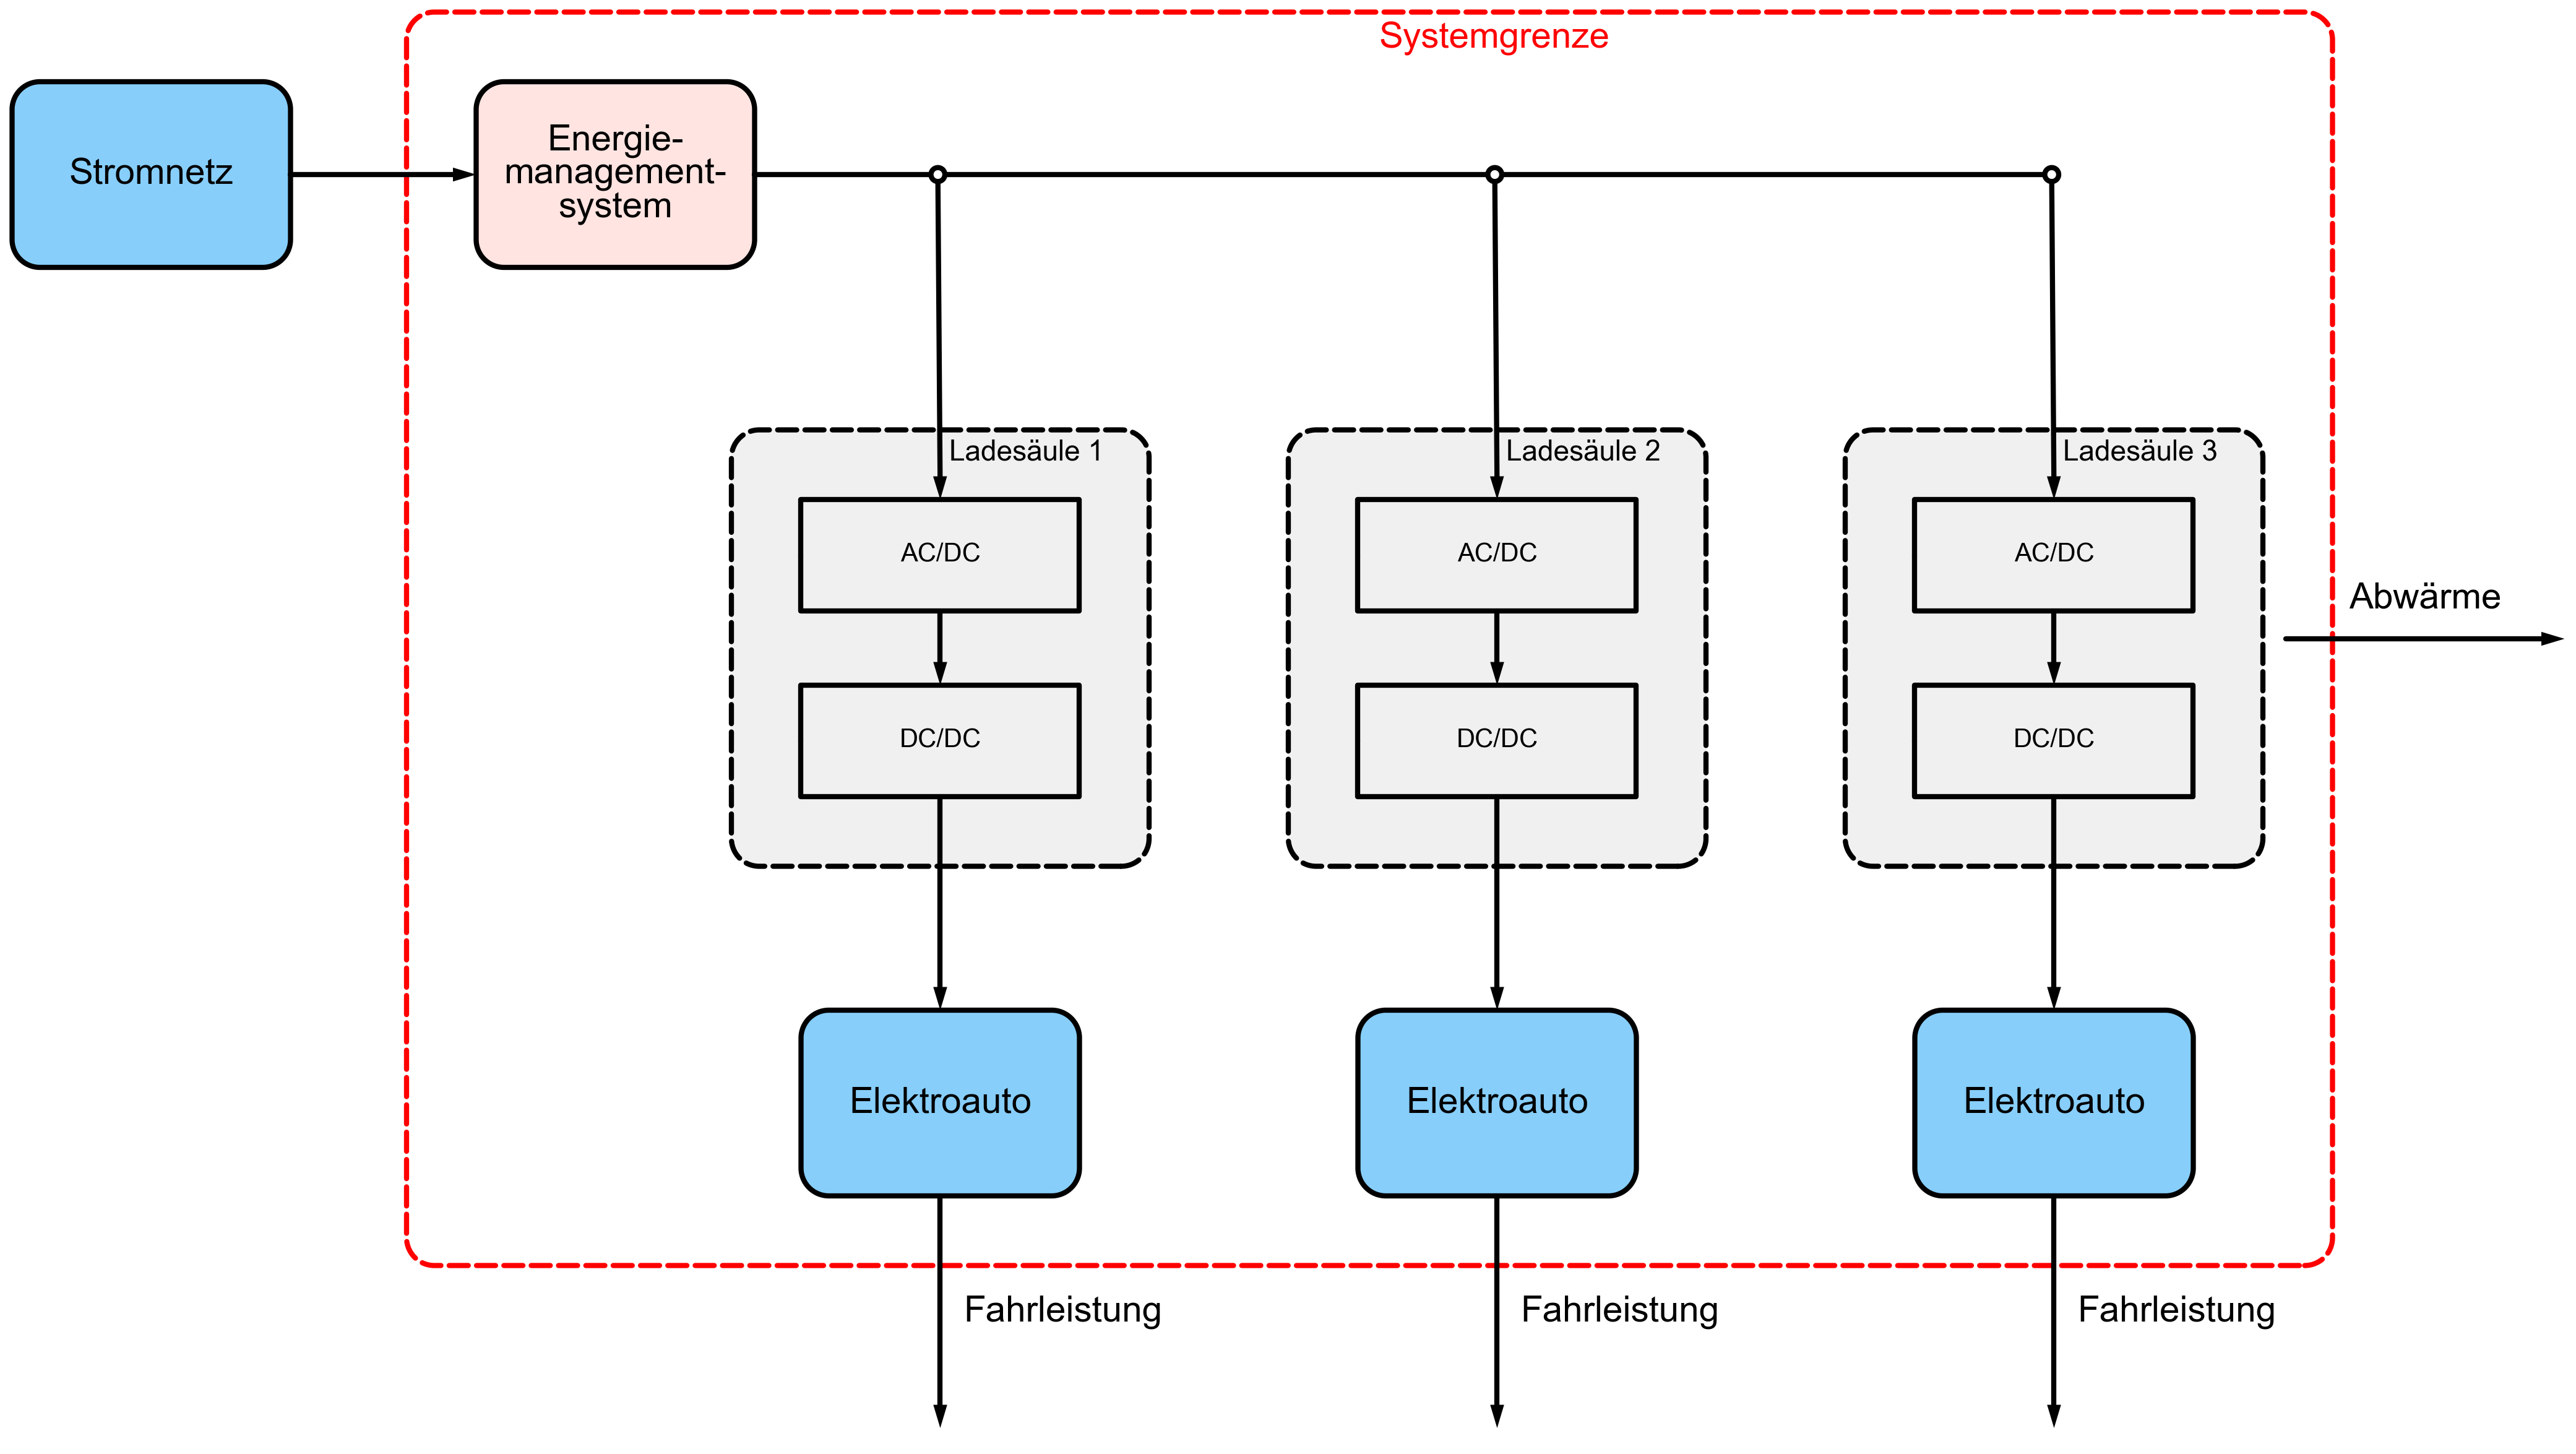

In [19]:
skizze(0)

#### 5.3 Annahmen und Anpassen des Datensatzes

Im Folgenden Abschnitt werden die Daten aufbereitet, um sie in den späteren Maßnahmen zu nutzen. Dabei wurden Lücken in den Messreihen mit vorhandenen Daten aus dem folgenden Jahr überschrieben.
Zusätzlich wurde ein neuer Datenframe erzeugt der die Zeit auf ein gesamtes Jahr begrenzt, für Maßnahme 1.

In [20]:
# edit Ladepunkt 2

df2_edit = df2.sort_index()
df2_edit.index = pd.to_datetime(df2.index)

# Ziel: April 2020 überschreiben
t0_start = pd.Timestamp("2020-03-13 00:00:00")
t0_end   = pd.Timestamp("2020-04-08 00:00:00")  # falls 5-min Raster; sonst einfach "2020-04-30 23:59:59"

# Quelle: April 2021
t1_start = t0_start + pd.DateOffset(years=1)
t1_end   = t0_end   + pd.DateOffset(years=1)

# 1) Werte aus April 2021 holen (nur die Spalte)
src = df2_edit.loc[t1_start:t1_end, "active_power_total"].copy()

# 2) Index um 1 Jahr zurück -> passt auf April 2020 Zeitstempel
src.index = src.index - pd.DateOffset(years=1)

# 3) Exakt auf die Ziel-Zeitstempel ausrichten (damit nichts "verrutscht")
target_index = df2_edit.loc[t0_start:t0_end].index
src_aligned = src.reindex(target_index)

# 4) Überschreiben in April 2020 (nur active_power_total)
df2_edit.loc[t0_start:t0_end, "active_power_total"] = src_aligned.values


# Ladepunkt 3 edit

df3_edit = df3.sort_index()
df3_edit.index = pd.to_datetime(df3.index)

# Zeitraum 1
t0_start = pd.Timestamp("2020-03-13 00:00:00")
t0_end   = pd.Timestamp("2020-04-08 00:00:00")

t1_start = t0_start + pd.DateOffset(years=1)
t1_end   = t0_end   + pd.DateOffset(years=1)

src = df3_edit.loc[t1_start:t1_end, "active_power_total"].copy()
src.index = src.index - pd.DateOffset(years=1)
target_index = df3_edit.loc[t0_start:t0_end].index
src_aligned = src.reindex(target_index)

df3_edit.loc[t0_start:t0_end, "active_power_total"] = src_aligned.values

# Zeitraum 2
t0_start = pd.Timestamp("2020-04-18 00:00:00")
t0_end   = pd.Timestamp("2020-04-27 00:00:00")

t1_start = t0_start + pd.DateOffset(years=1)
t1_end   = t0_end   + pd.DateOffset(years=1)

src = df3_edit.loc[t1_start:t1_end, "active_power_total"].copy()
src.index = src.index - pd.DateOffset(years=1)
target_index = df3_edit.loc[t0_start:t0_end].index
src_aligned = src.reindex(target_index)

df3_edit.loc[t0_start:t0_end, "active_power_total"] = src_aligned.values

# Zeitraum 3
t0_start = pd.Timestamp("2020-07-18 00:00:00")
t0_end   = pd.Timestamp("2020-08-06 00:00:00")

t1_start = t0_start + pd.DateOffset(years=1)
t1_end   = t0_end   + pd.DateOffset(years=1)

src = df3_edit.loc[t1_start:t1_end, "active_power_total"].copy()
src.index = src.index - pd.DateOffset(years=1)
target_index = df3_edit.loc[t0_start:t0_end].index
src_aligned = src.reindex(target_index)

df3_edit.loc[t0_start:t0_end, "active_power_total"] = src_aligned.values

# Zeitraum 4
t0_start = pd.Timestamp("2020-10-17 00:00:00")
t0_end   = pd.Timestamp("2020-12-02 00:00:00")

t1_start = t0_start + pd.DateOffset(months=3)
t1_end   = t0_end   + pd.DateOffset(months=3)

src = df3_edit.loc[t1_start:t1_end, "active_power_total"].copy()
src.index = src.index - pd.DateOffset(months=3)
target_index = df3_edit.loc[t0_start:t0_end].index
src_aligned = src.reindex(target_index)

df3_edit.loc[t0_start:t0_end, "active_power_total"] = src_aligned.values


# Ladepunkt 4 edit

df4_edit = df4.sort_index()
df4_edit.index = pd.to_datetime(df4.index)

# Zeitraum 1
t0_start = pd.Timestamp("2020-03-13 00:00:00")
t0_end   = pd.Timestamp("2020-04-07 00:00:00")

t1_start = t0_start + pd.DateOffset(years=1)
t1_end   = t0_end   + pd.DateOffset(years=1)

src = df4_edit.loc[t1_start:t1_end, "active_power_total"].copy()
src.index = src.index - pd.DateOffset(years=1)
target_index = df4_edit.loc[t0_start:t0_end].index
src_aligned = src.reindex(target_index)

df4_edit.loc[t0_start:t0_end, "active_power_total"] = src_aligned.values

# Zeitraum 2
t0_start = pd.Timestamp("2020-05-27 00:00:00")
t0_end   = pd.Timestamp("2020-06-03 00:00:00")

t1_start = t0_start + pd.DateOffset(years=1)
t1_end   = t0_end   + pd.DateOffset(years=1)

src = df4_edit.loc[t1_start:t1_end, "active_power_total"].copy()
src.index = src.index - pd.DateOffset(years=1)
target_index = df4_edit.loc[t0_start:t0_end].index
src_aligned = src.reindex(target_index)

df4_edit.loc[t0_start:t0_end, "active_power_total"] = src_aligned.values


#Jahr 2020 auswählen
df2_edit_2020 = df2_edit.loc['2020-01-01':'2020-12-31 23:55'].copy()
df3_edit_2020 = df3_edit.loc['2020-01-01':'2020-12-31 23:55'].copy()
df4_edit_2020 = df4_edit.loc['2020-01-01':'2020-12-31 23:55'].copy()

df2_edit_2020.to_csv("data/Data_edit_2020/df2_edit_2020.csv", index=True)
df3_edit_2020.to_csv("data/Data_edit_2020/df3_edit_2020.csv", index=True)
df4_edit_2020.to_csv("data/Data_edit_2020/df4_edit_2020.csv", index=True)
print(df2_edit_2020.head())

OSError: Cannot save file into a non-existent directory: 'data\Data_edit_2020'

In [28]:
import pandas as pd

# DataFrames in Liste zusammenfassen
df_list = [
    df2_edit_2020,
    df3_edit_2020,
    df4_edit_2020
]

# Aneinanderketten (untereinander)
df_edit_all = pd.concat(
    df_list,
    axis=0,          # Zeilenweise
    ignore_index=False
)

# Kontrolle
display(df_edit_all.head())
print("Anzahl Zeilen gesamt:", len(df_edit_all))


,process_id,charging_point_id,active_power_total
2020-01-01 00:00:00,NaN,2.0,0.0
2020-01-01 00:05:00,NaN,2.0,0.0
2020-01-01 00:10:00,NaN,2.0,0.0
2020-01-01 00:15:00,NaN,2.0,0.0
2020-01-01 00:20:00,NaN,2.0,0.0


Anzahl Zeilen gesamt: 316224


#### Leistungsverlauf der Datenquelle an Ladepunkt 3

<Axes: title={'center': 'df3'}>

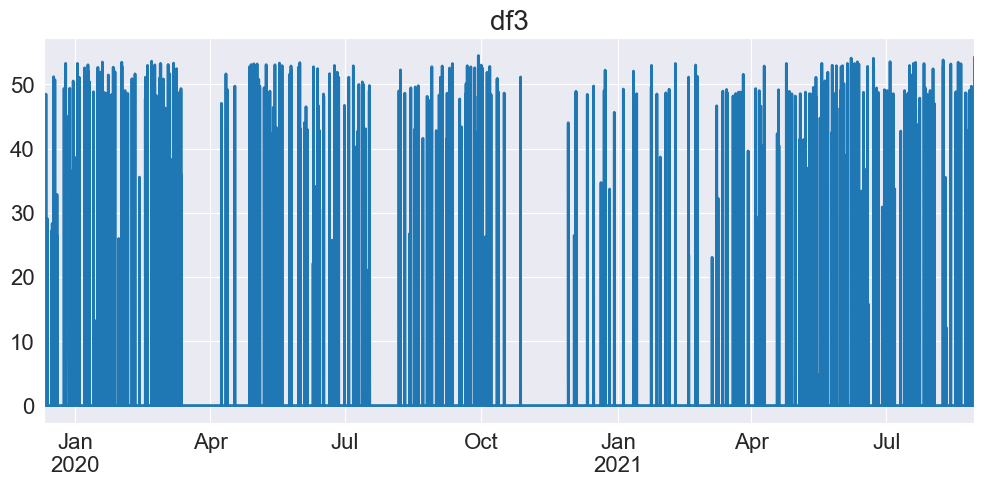

In [29]:
df3['active_power_total'].plot(title='df3', figsize=(12, 5))

#### Leistungsverlauf der angepassent Datenreihe an Ladepunkt 3

<Axes: title={'center': 'df3_edit'}>

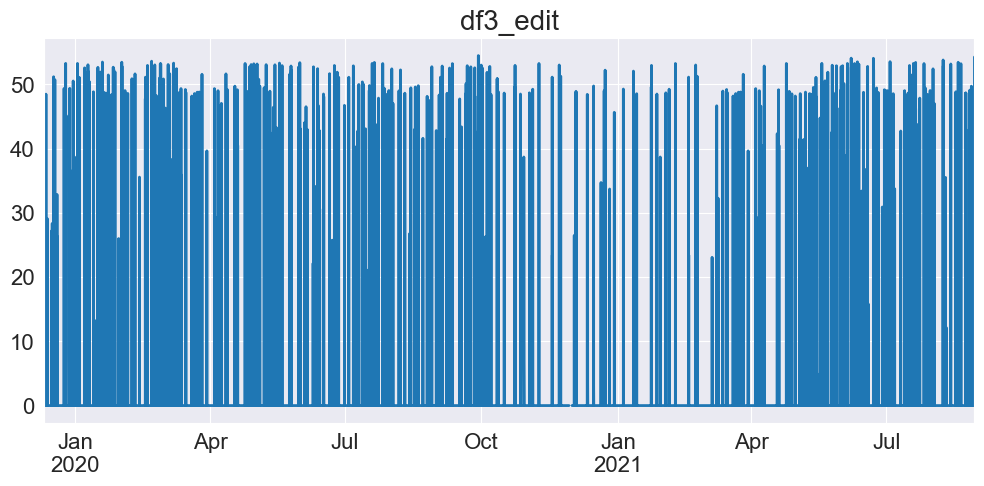

In [30]:
df3_edit['active_power_total'].plot(title='df3_edit', figsize=(12, 5))

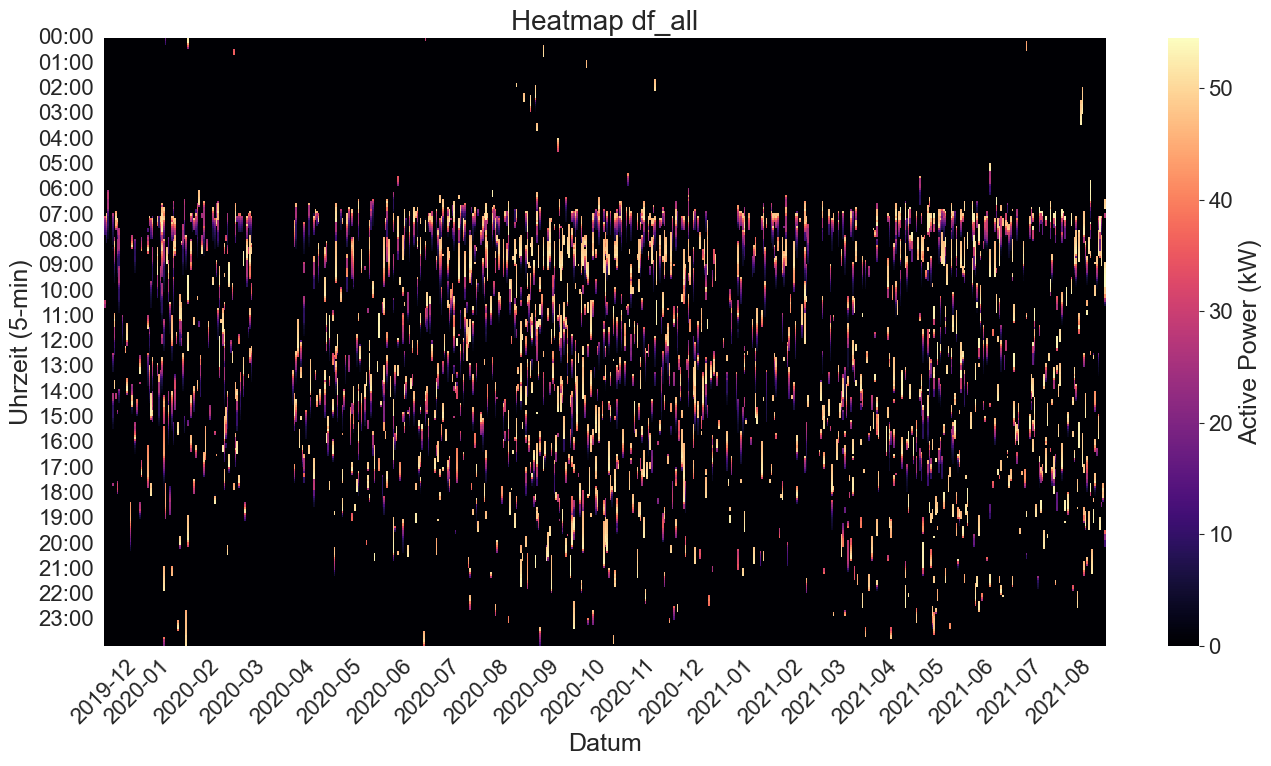

In [31]:
plot_charging_heatmap_null(df_all, title='Heatmap df_all')

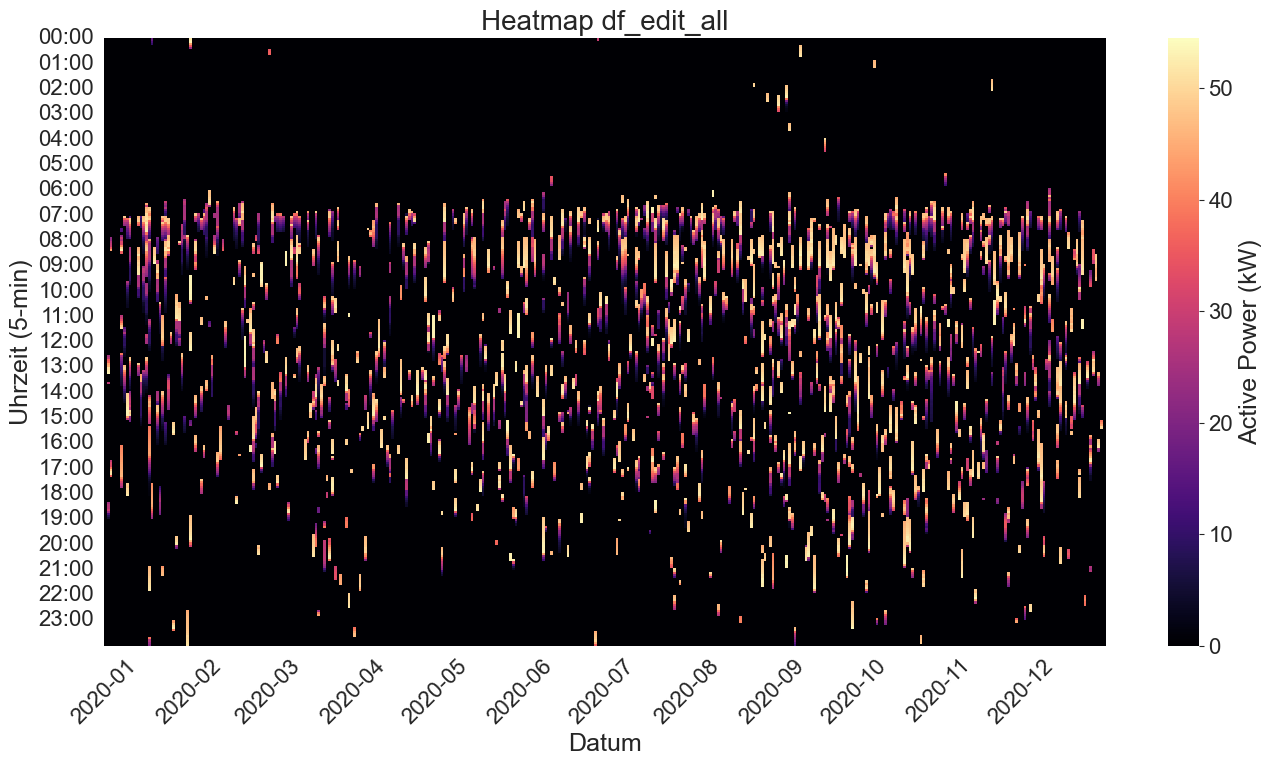

In [32]:
plot_charging_heatmap_null(df_edit_all, title='Heatmap df_edit_all')

In [33]:
stats3_edit = compute_stats_df(df_edit_all, process_ids=process_ids_3)
print(stats3_edit.drop(columns=["start", "end",'n_points']))
print(stats3_edit.describe().drop(columns=['charging_point_id','start','end','n_points']))

            charging_point_id  duration_h  mean_power  max_power  energy_kWh
process_id                                                                  
841.0                     3.0    0.833333   33.900538  53.263435   31.069413
842.0                     3.0    0.166667    9.486825  28.288433    2.365676
843.0                     3.0    0.750000   15.826262  30.147343   13.182350
844.0                     3.0    0.666667   23.291822  43.462593   17.462683
845.0                     3.0    0.750000   31.819348  51.106613   26.510067
...                       ...         ...         ...        ...         ...
1051.0                    3.0    1.500000   25.686872  34.719685   40.666471
1052.0                    3.0    0.333333   27.977443  49.018875   11.652696
1053.0                    3.0    1.500000   43.901489  52.218033   69.506052
1054.0                    3.0    0.750000   21.022567  33.714722   17.513648
1055.0                    3.0    0.666667   24.869913  45.654057   18.647925